In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")
df = pd.read_csv(r"C:\Users\jacob\Downloads\amazon_sales_eda_project\data\amazon_sales_raw.csv")
print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (10000, 12)


,order_id,order_date,product,category,region,quantity,price,discount,sales,cost,profit,payment_method
0,AMZ106252,2024-07-16,Storage Organizer,Home & Kitchen,West,3,2785.15,0.20,6684.36,6066.72,617.64,Cash on Delivery
1,AMZ104684,NaN,Yoga Mat,Sports,North,1,4843.76,0.15,4117.20,3500.13,617.07,Credit Card
2,AMZ101731,2025-08-04,Webcam,Electronics,North,2,21445.08,0.20,34312.13,31807.43,2504.70,Net Banking
3,AMZ104742,2025-07-27,Hair Dryer,Beauty,West,2,2365.38,0.05,4494.22,2971.86,1522.36,Net Banking
4,AMZ104521,2025-07-28,Storage Organizer,Home & Kitchen,West,1,3547.12,0.15,3015.05,2494.38,520.67,Net Banking


## 1. Initial inspection

In [2]:
print("Rows and columns:", df.shape)
display(df.info())
display(df.describe(include="all").T)
print("Duplicate rows:", df.duplicated().sum())
print("\nMissing values by column:")
display(df.isna().sum().sort_values(ascending=False))

Rows and columns: (10000, 12)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   order_id        10000 non-null  object 
 1   order_date      9980 non-null   object 
 2   product         10000 non-null  object 
 3   category        10000 non-null  object 
 4   region          9931 non-null   object 
 5   quantity        10000 non-null  int64  
 6   price           9965 non-null   float64
 7   discount        9948 non-null   float64
 8   sales           10000 non-null  float64
 9   cost            10000 non-null  float64
 10  profit          10000 non-null  float64
 11  payment_method  9958 non-null   object 
dtypes: float64(5), int64(1), object(6)
memory usage: 937.6+ KB


None

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
order_id,10000,9700,AMZ105240,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
order_date,9980,1096,2023-12-16,18,NaN,NaN,NaN,NaN,NaN,NaN,NaN
product,10000,30,Webcam,500,NaN,NaN,NaN,NaN,NaN,NaN,NaN
category,10000,6,Electronics,2421,NaN,NaN,NaN,NaN,NaN,NaN,NaN
region,9931,5,South,2408,NaN,NaN,NaN,NaN,NaN,NaN,NaN
quantity,10000.0,NaN,NaN,NaN,2.2051,1.335894,1.0,1.0,2.0,3.0,6.0
price,9965.0,NaN,NaN,NaN,6752.348532,8248.439057,173.15,1483.78,3418.47,7465.43,43299.02
discount,9948.0,NaN,NaN,NaN,0.13944,0.096923,0.0,0.05,0.15,0.2,0.4
sales,10000.0,NaN,NaN,NaN,13225.256208,20586.464263,157.2,2287.0025,5466.64,14598.2825,213955.68
cost,10000.0,NaN,NaN,NaN,11003.897192,17672.106231,111.44,1690.935,4219.275,11756.225,195649.13


Duplicate rows: 300

Missing values by column:


region            69
discount          52
payment_method    42
price             35
order_date        20
order_id           0
product            0
category           0
quantity           0
sales              0
cost               0
profit             0
dtype: int64

## 2. Data cleaning

In [3]:
clean = df.copy()
clean["order_date"] = pd.to_datetime(clean["order_date"], errors="coerce")
duplicates_before = clean.duplicated().sum()
clean = clean.drop_duplicates().copy()
clean["discount"] = clean["discount"].fillna(0)
clean["price"] = clean["price"].fillna(clean.groupby("product")["price"].transform("median"))
clean["price"] = clean["price"].fillna(clean["price"].median())
for col in ["region", "payment_method"]:
    clean[col] = clean[col].fillna(clean[col].mode().iloc[0])
seasonal_factor = np.where(clean["order_date"].dt.month.isin([10, 11, 12]), 1.15, 1.0)
seasonal_factor = pd.Series(seasonal_factor, index=clean.index).fillna(1.0)
clean["sales"] = (clean["quantity"] * clean["price"] * (1 - clean["discount"]) * seasonal_factor).round(2)
clean["profit"] = (clean["sales"] - clean["cost"]).round(2)
print("Duplicates removed:", duplicates_before)
print("Rows after duplicate removal:", len(clean))
print("\nMissing values after cleaning:")
display(clean.isna().sum())
display(clean.head())

Duplicates removed: 300
Rows after duplicate removal: 9700

Missing values after cleaning:


order_id           0
order_date        18
product            0
category           0
region             0
quantity           0
price              0
discount           0
sales              0
cost               0
profit             0
payment_method     0
dtype: int64

,order_id,order_date,product,category,region,quantity,price,discount,sales,cost,profit,payment_method
0,AMZ106252,2024-07-16,Storage Organizer,Home & Kitchen,West,3,2785.15,0.20,6684.36,6066.72,617.64,Cash on Delivery
1,AMZ104684,NaT,Yoga Mat,Sports,North,1,4843.76,0.15,4117.20,3500.13,617.07,Credit Card
2,AMZ101731,2025-08-04,Webcam,Electronics,North,2,21445.08,0.20,34312.13,31807.43,2504.70,Net Banking
3,AMZ104742,2025-07-27,Hair Dryer,Beauty,West,2,2365.38,0.05,4494.22,2971.86,1522.36,Net Banking
4,AMZ104521,2025-07-28,Storage Organizer,Home & Kitchen,West,1,3547.12,0.15,3015.05,2494.38,520.67,Net Banking


## 3. Feature engineering

In [4]:
clean["year"] = clean["order_date"].dt.year
clean["month"] = clean["order_date"].dt.month
clean["month_name"] = clean["order_date"].dt.month_name()
clean["year_month"] = clean["order_date"].dt.to_period("M").astype(str)
clean["profit_margin_pct"] = np.where(clean["sales"] != 0, clean["profit"] / clean["sales"] * 100, np.nan)

display(clean.head())

,order_id,order_date,product,category,region,quantity,price,discount,sales,cost,profit,payment_method,year,month,month_name,year_month,profit_margin_pct
0,AMZ106252,2024-07-16,Storage Organizer,Home & Kitchen,West,3,2785.15,0.20,6684.36,6066.72,617.64,Cash on Delivery,2024.0,7.0,July,2024-07,9.240077
1,AMZ104684,NaT,Yoga Mat,Sports,North,1,4843.76,0.15,4117.20,3500.13,617.07,Credit Card,NaN,NaN,NaN,NaT,14.987613
2,AMZ101731,2025-08-04,Webcam,Electronics,North,2,21445.08,0.20,34312.13,31807.43,2504.70,Net Banking,2025.0,8.0,August,2025-08,7.299751
3,AMZ104742,2025-07-27,Hair Dryer,Beauty,West,2,2365.38,0.05,4494.22,2971.86,1522.36,Net Banking,2025.0,7.0,July,2025-07,33.873731
4,AMZ104521,2025-07-28,Storage Organizer,Home & Kitchen,West,1,3547.12,0.15,3015.05,2494.38,520.67,Net Banking,2025.0,7.0,July,2025-07,17.269034


## 4. Sales and profit KPIs

In [5]:
total_sales = clean["sales"].sum()
total_profit = clean["profit"].sum()
total_orders = clean["order_id"].nunique()
avg_order_value = clean.groupby("order_id")["sales"].sum().mean()
overall_margin = (total_profit / total_sales * 100) if total_sales else np.nan

kpis = pd.DataFrame({
    "Metric": ["Rows after cleaning", "Unique orders", "Total sales", "Total profit", "Average sales per order", "Overall profit margin (%)"],
    "Value": [len(clean), total_orders, total_sales, total_profit, avg_order_value, overall_margin]
})
display(kpis.round(2))

,Metric,Value
0,Rows after cleaning,9.700000e+03
1,Unique orders,9.700000e+03
2,Total sales,1.285153e+08
3,Total profit,2.170332e+07
4,Average sales per order,1.324900e+04
5,Overall profit margin (%),1.689000e+01


## 5. Sales by category

,total_sales,total_profit,units_sold,average_discount
category,,,,
Electronics,85550970.13,11397542.92,5119,0.14
Home & Kitchen,19390995.85,4338490.40,4412,0.14
Clothing,9039542.64,2401839.76,3627,0.14
Sports,8456443.43,1782007.51,2461,0.14
Beauty,4058173.29,1160201.88,3024,0.14
Books,2019194.60,623234.23,2778,0.14


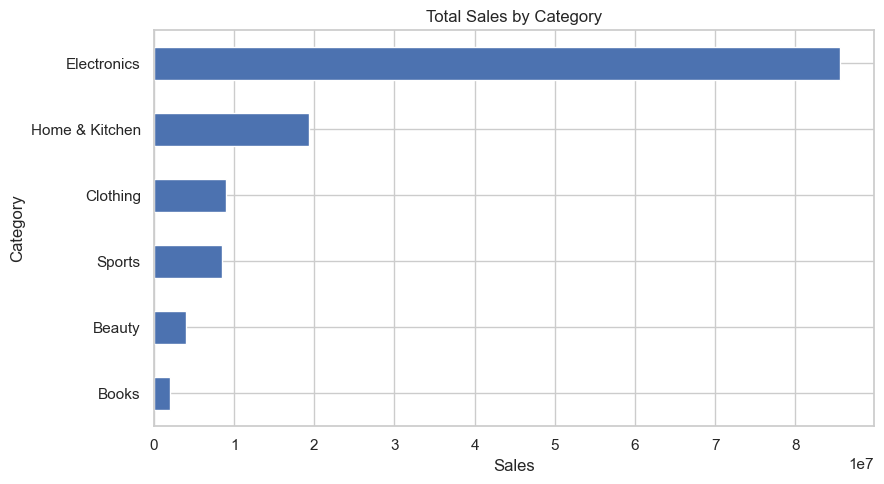

In [6]:
category_summary = clean.groupby("category", dropna=False).agg(
    total_sales=("sales", "sum"),
    total_profit=("profit", "sum"),
    units_sold=("quantity", "sum"),
    average_discount=("discount", "mean")
).sort_values("total_sales", ascending=False)

display(category_summary.round(2))

category_summary["total_sales"].sort_values().plot(kind="barh", figsize=(9,5), title="Total Sales by Category")
plt.xlabel("Sales")
plt.ylabel("Category")
plt.tight_layout()
plt.show()

## 6. Sales by region

,total_sales,total_profit,orders
region,,,
South,31592987.45,5340751.72,2396
West,28697085.20,4888913.36,2249
North,27676386.15,4710589.63,2098
East,20307720.11,3517325.08,1490
Central,20241141.03,3245736.91,1467


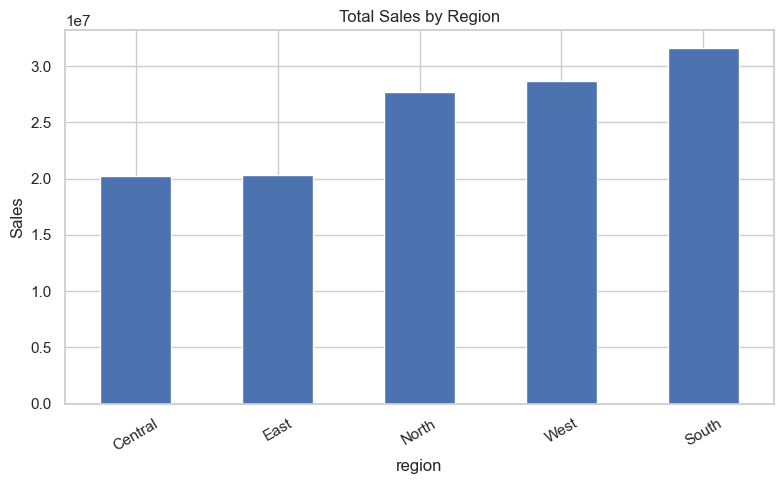

In [7]:
region_summary = clean.groupby("region").agg(
    total_sales=("sales", "sum"),
    total_profit=("profit", "sum"),
    orders=("order_id", "nunique")
).sort_values("total_sales", ascending=False)

display(region_summary.round(2))
region_summary["total_sales"].sort_values().plot(kind="bar", figsize=(8,5), title="Total Sales by Region")
plt.ylabel("Sales")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

## 7. Monthly sales trend

,total_sales,total_profit
order_date,,
2023-01-01,2752615.11,446206.14
2023-02-01,2981221.89,354887.90
2023-03-01,3811929.37,523243.48
2023-04-01,3423737.56,487298.45
2023-05-01,3181693.22,493988.13


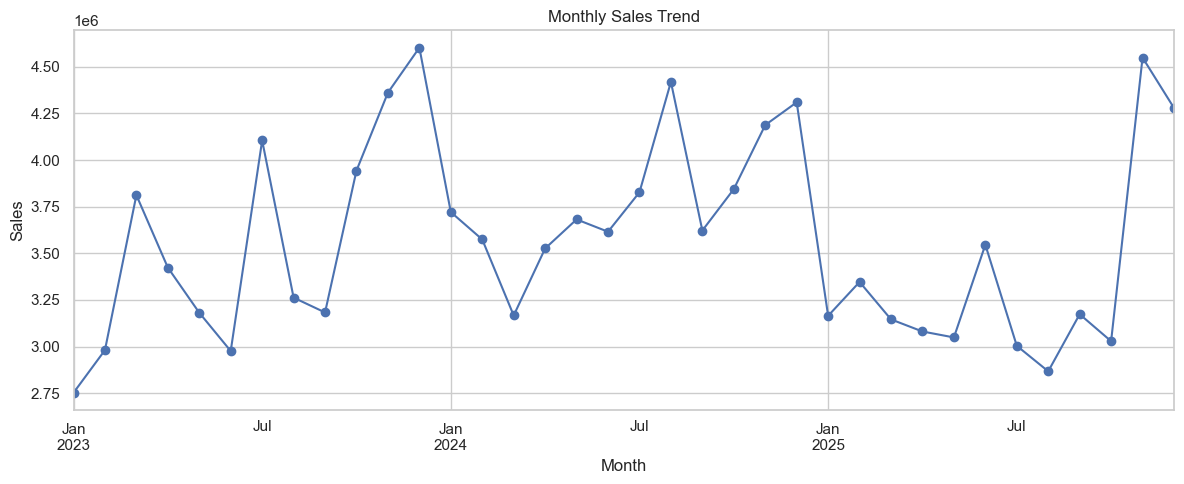

,total_sales
Jan,9638724.34
Feb,9902083.58
Mar,10124788.39
Apr,10030977.91
May,9912668.37
Jun,10138175.14
Jul,10936650.36
Aug,10548800.01
Sep,9978892.42
Oct,10816707.88


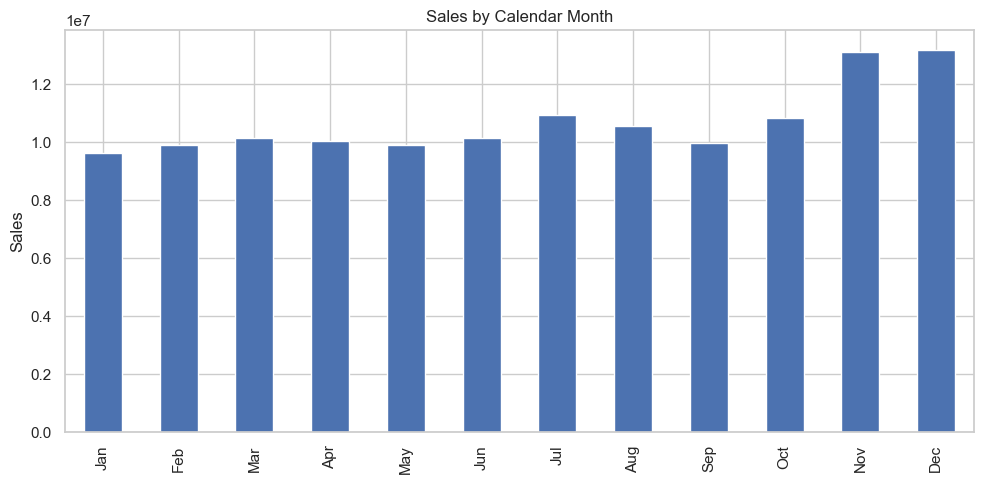

In [8]:
monthly = clean.dropna(subset=["order_date"]).set_index("order_date").resample("MS").agg(
    total_sales=("sales", "sum"),
    total_profit=("profit", "sum")
)
display(monthly.head())

monthly["total_sales"].plot(figsize=(12,5), marker="o", title="Monthly Sales Trend")
plt.ylabel("Sales")
plt.xlabel("Month")
plt.tight_layout()
plt.show()

# Compared sales across calendar months (Jan-Dec)
month_order = list(range(1,13))
seasonal_summary = clean.dropna(subset=["order_date"]).groupby(clean["order_date"].dt.month)["sales"].sum().reindex(month_order)
seasonal_summary.index = ["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"]
display(seasonal_summary.to_frame("total_sales"))
seasonal_summary.plot(kind="bar", figsize=(10,5), title="Sales by Calendar Month")
plt.ylabel("Sales")
plt.tight_layout()
plt.show()

## 8. Top products

,total_sales,total_profit,units_sold
product,,,
Wireless Earbuds,18143547.39,2634257.40,1055
Bluetooth Speaker,17792002.36,2432804.99,1068
Webcam,17296885.91,2069203.36,1066
USB-C Hub,16268175.89,2065616.08,964
Smart Watch,16050358.58,2195661.09,966
Desk Lamp,4283697.13,966964.99,969
Blender,4038307.03,860823.71,952
Storage Organizer,3904812.53,912905.61,859
Air Fryer,3707019.56,836393.46,844


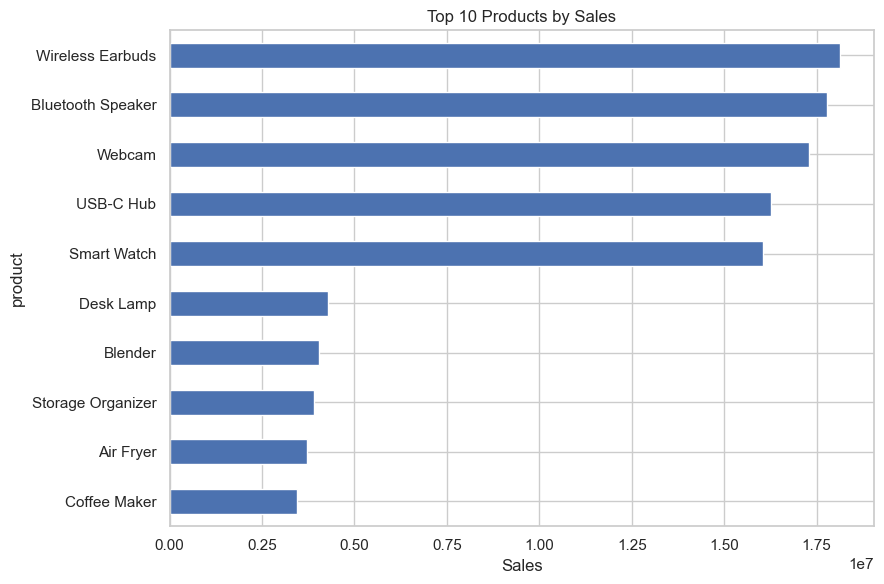

In [9]:
top_products = clean.groupby("product").agg(
    total_sales=("sales", "sum"),
    total_profit=("profit", "sum"),
    units_sold=("quantity", "sum")
).sort_values("total_sales", ascending=False).head(10)

display(top_products.round(2))
top_products["total_sales"].sort_values().plot(kind="barh", figsize=(9,6), title="Top 10 Products by Sales")
plt.xlabel("Sales")
plt.tight_layout()
plt.show()

## 9. Discount analysis

,orders,average_sales,average_profit,total_profit,average_margin_pct
discount_band,,,,,
0-5%,2663,15992.22,4250.86,11320043.78,31.56
Above 5-15%,3736,12766.04,2300.68,8595349.29,23.67
Above 15-25%,2428,12094.63,965.61,2344489.85,14.28
Above 25%,873,10158.46,-637.53,-556566.22,0.12


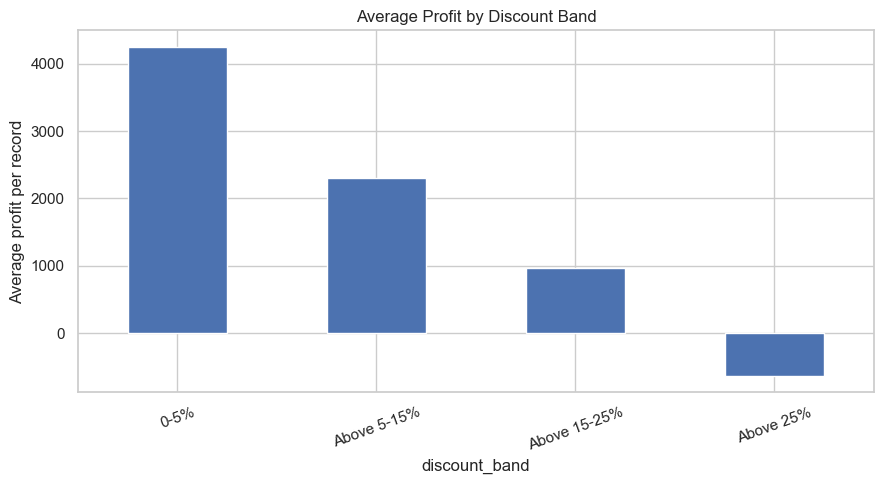

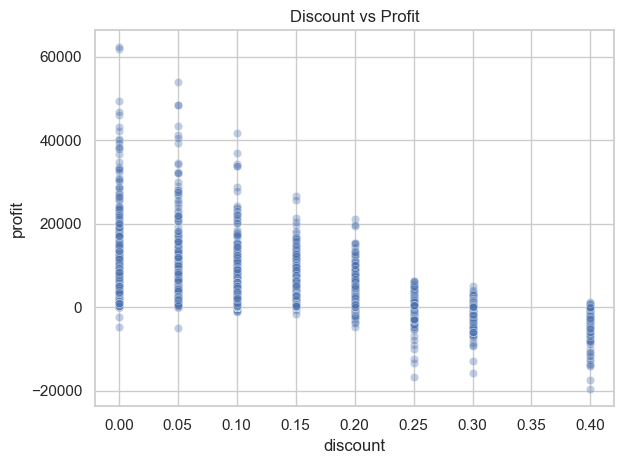

In [10]:
clean["discount_band"] = pd.cut(
    clean["discount"],
    bins=[-0.001, 0.05, 0.15, 0.25, 0.401],
    labels=["0-5%", "Above 5-15%", "Above 15-25%", "Above 25%"]
)

discount_summary = clean.groupby("discount_band", observed=False).agg(
    orders=("order_id", "nunique"),
    average_sales=("sales", "mean"),
    average_profit=("profit", "mean"),
    total_profit=("profit", "sum"),
    average_margin_pct=("profit_margin_pct", "mean")
)
display(discount_summary.round(2))

discount_summary["average_profit"].plot(kind="bar", figsize=(9,5), title="Average Profit by Discount Band")
plt.ylabel("Average profit per record")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

sns.scatterplot(data=clean, x="discount", y="profit", alpha=0.35)
plt.title("Discount vs Profit")
plt.tight_layout()
plt.show()

## 10. Distribution and correlation

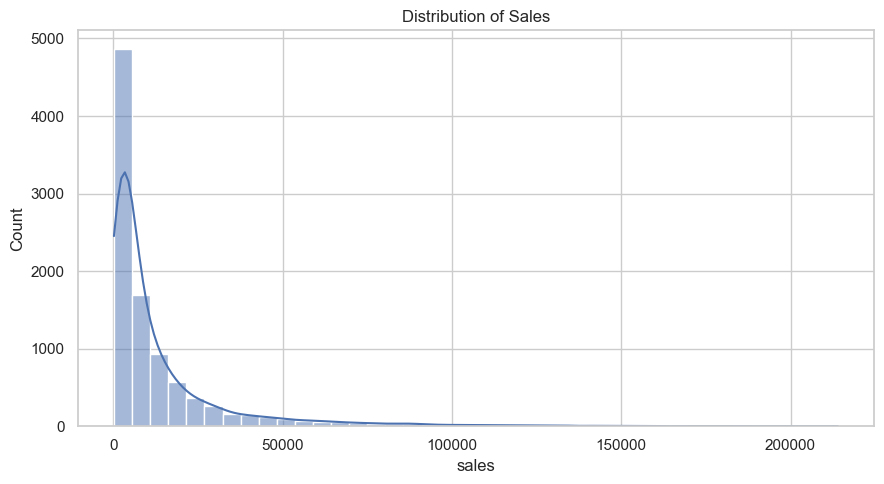

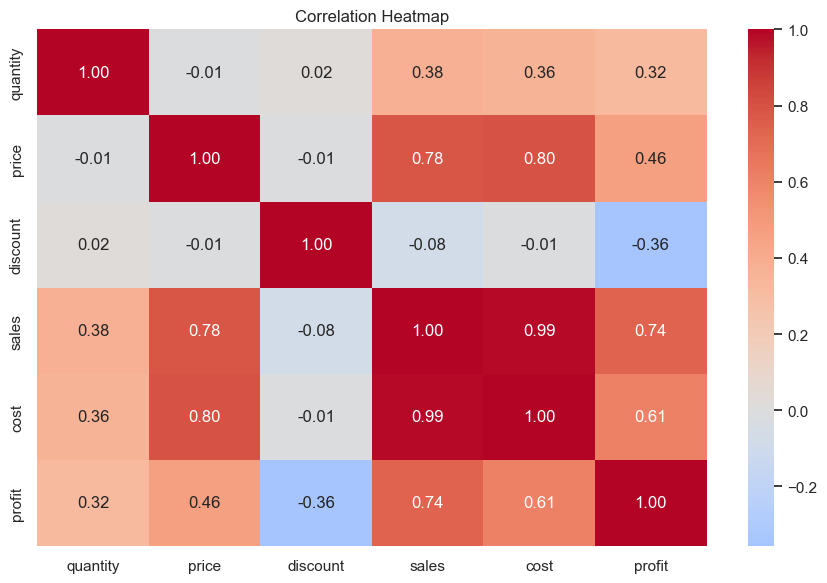

In [11]:
fig, ax = plt.subplots(figsize=(9,5))
sns.histplot(data=clean, x="sales", bins=40, kde=True, ax=ax)
ax.set_title("Distribution of Sales")
plt.tight_layout()
plt.show()

numeric_cols = ["quantity", "price", "discount", "sales", "cost", "profit"]
corr = clean[numeric_cols].corr(numeric_only=True)
plt.figure(figsize=(9,6))
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f", center=0)
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

## 11. Pivot table

In [12]:
sales_pivot = pd.pivot_table(
    clean,
    index="category",
    columns="region",
    values="sales",
    aggfunc="sum",
    fill_value=0
)
display(sales_pivot.round(2))

region,Central,East,North,South,West
category,,,,,
Beauty,750753.30,575029.22,781020.56,1068208.42,883161.79
Books,311223.19,315097.67,428684.77,495954.34,468234.63
Clothing,1338695.51,1415340.44,1846423.31,2270960.27,2168123.11
Electronics,13418616.81,13888409.03,18459180.66,21175731.33,18609032.30
Home & Kitchen,2944625.94,2867597.02,4395910.33,4572557.84,4610304.72
Sports,1477226.28,1246246.73,1765166.52,2009575.25,1958228.65


## 12. Findings and recommendations

In [14]:
best_category = category_summary["total_sales"].idxmax()
best_region = region_summary["total_sales"].idxmax()
best_product = top_products["total_sales"].idxmax()

print(f"Highest-revenue category in this dataset: {best_category}")
print(f"Highest-revenue region in this dataset: {best_region}")
print(f"Top product by revenue among all products: {best_product}")

Highest-revenue category in this dataset: Electronics
Highest-revenue region in this dataset: South
Top product by revenue among all products: Wireless Earbuds


13. Conclusion —

- Analyzed a synthetic sales dataset containing 10,000 records and 12 columns using Python, Pandas and NumPy; removed 300 duplicate rows, handled missing values and converted order dates to datetime format.
- Explored sales and profitability by category, region, month and discount band using Pandas `groupby`, pivot tables and visualizations, including bar charts, line charts, histograms and a correlation heatmap.
- Identified Electronics as the highest-sales category and the South as the top-performing region by sales; observed that November and December had the highest monthly sales.
- Found that average profit declined across higher discount bands, falling from approximately 4,250.86 in the 0–5% band to −637.53 in the above-25% band.
- Recommended prioritizing inventory and marketing for high-performing categories and regions while reviewing steep discounts to reduce the risk of unprofitable sales.